# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170215  # <-- your full roll number
NAME = "Aman Jha"     # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170215   Name: Aman Jha   Fingerprint: E5CE7EFD   Tickets: 12

Ticket_ID                                                                               Ticket_Text
      T01                                               I can't login and I didn't change anything.
      T02                                 I can't open the lms since yesterday. Can you check this?
      T03                I tried restarting the Python after restarting the system. This is urgent.
      T04                                   The password keeps asking for login. Please resolve it.
      T05      I was locked out of the MATLAB when I use mobile hotspot. I don't know what changed.
      T06       I tried restarting the server while uploading the file. I have tried several times!
      T07 Projector crashes while opening when I use mobile hotspot. The same problem occurs again.
      T08 Student portal failed to open before the assignment deadline. I have tried several times!
      T09           

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
import re
from collections import Counter

results = {tid: process_ticket(txt) for tid, txt in zip(df.Ticket_ID, df.Ticket_Text)}

rows = []
for tid, r in results.items():
    rows.append({"Ticket_ID": tid,
                 "Sentences": len(r["sentences"]),
                 "Tokens": len(r["tokens"]),
                 "Punctuation": len(r["punct"]),
                 "Stopwords": len(r["stops"]),
                 "Unique_Tokens": len(set(r["tokens"])),
                 "Final_Tokens": len(r["final"])})
q1 = pd.DataFrame(rows)
total = q1.drop(columns="Ticket_ID").sum()
total["Ticket_ID"] = "TOTAL"
q1 = pd.concat([q1, total.to_frame().T], ignore_index=True)
print(q1.to_string(index=False))

all_tokens = [t for r in results.values() for t in r["tokens"]]
print("\nUnique tokens in the whole corpus:", len(set(all_tokens)))

sel = FOCUS[0]
r = results[sel]
print(f"\nTicket {sel}: {df.loc[df.Ticket_ID == sel, 'Ticket_Text'].iloc[0]}")
print("Tokens      :", r["tokens"])
print("Punctuation :", r["punct"])
print("Stopwords   :", r["stops"])
print("Final tokens:", r["final"])

Ticket_ID Sentences Tokens Punctuation Stopwords Unique_Tokens Final_Tokens
      T01         1     11           1         4             9            6
      T02         2     14           2         5            14            7
      T03         2     14           2         6            11            6
      T04         2     11           2         3            10            6
      T05         2     20           2        10            17            8
      T06         2     16           2         6            13            8
      T07         2     16           2         6            15            8
      T08         2     16           2         5            16            9
      T09         2     15           2         6            15            7
      T10         1      6           1         1             6            4
      T11         2     10           4         2             9            4
      T12         1      7           2         1             7            4
    TOTAL   

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In my data the odd ones are `ca` and `n't` (from "can't" in T01 and T02, "didn't" in T01 and "don't" in T05), and `//lms.thapar.edu/help` from the URL in T12. `3.12` from T10 is also left in, though it's a number rather than a word.

They all come from word_tokenize(). It follows Penn Treebank rules, so "can't" becomes `ca` + `n't` and "didn't" becomes `did` + `n't`. `did` and `do` are stopwords and get removed, but `ca` and `n't` aren't in the NLTK stopword list, so they end up in the final tokens. The URL gets split at the colon into `https`, `:` and `//lms.thapar.edu/help`. The colon is removed as punctuation, and the leftover piece doesn't count as punctuation because it contains letters.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

B, E = r"(?<![\w'.@/:-])", r"(?![\w@]|\.\w)"
LONG_WORD = r"(?<![\w'.@/:])[A-Za-z]{6,}" + E
NUMBER    = r"\b0x[0-9A-Fa-f]+\b|(?<![\w.])\d+(?:[.,]\d+)*(?!\w)"
CAPITAL   = B + r"[A-Z][A-Za-z]*(?:[-'][A-Za-z]+)*" + E
VOWEL     = B + r"[AEIOUaeiou][A-Za-z]*(?:[-'][A-Za-z]+)*" + E

EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL   = r"(?:https?://|www\.)[^\s,;]+?(?=[.,;!?)]*(?:\s|$))"
PHONE = r"(?:\+\d{1,3}[\s-]?)?(?<!\d)\d{5}[\s-]?\d{5}(?!\d)|(?<!\d)0\d{2,4}[\s-]\d{3}[\s-]\d{4}(?!\d)"

def extract(text):
    return {"long words": re.findall(LONG_WORD, text),
            "numbers": re.findall(NUMBER, text),
            "capitalized": re.findall(CAPITAL, text),
            "vowel words": re.findall(VOWEL, text)}

def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    return re.sub(PHONE, "<PHONE>", text)

def show(label, text):
    print(f"\n{label}: {text}")
    for k, v in extract(text).items():
        print(f"  {k:12}: {v}")
    print(f"  {'masked':12}: {mask(text)}")

print("TEST_LINES")
for i, line in enumerate(TEST_LINES, 1):
    show(f"L{i}", line)

print("\n\nMy tickets")
for tid, txt in zip(df.Ticket_ID, df.Ticket_Text):
    show(tid, txt)

start, middle = [], []
for r in results.values():
    for s in r["sentences"]:
        for m in re.finditer(CAPITAL, s):
            if s[:m.start()].strip(string.punctuation + " ") == "":
                start.append(m.group())
            else:
                middle.append(m.group())
print(f"\nCapitalized words: {len(start) + len(middle)}")
print(f"At the start of a sentence: {len(start)} {start}")
print(f"Inside a sentence: {len(middle)} {middle}")

TEST_LINES

L1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  long words  : []
  numbers     : []
  capitalized : ['Mail']
  vowel words : ['or', 'or']
  masked      : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

L2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  long words  : ['Version']
  numbers     : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  capitalized : ['Call', 'Version', 'Rs']
  vowel words : ['or', 'is']
  masked      : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

L3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  long words  : []
  numbers     : ['5.30']
  capitalized : ['The']
  vowel words : ["isn't", 'open', 'at']
  masked      : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


My tickets

T01: I can't login and I d

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* My tickets have 27 capitalized words, and 21 of them are capitalized only because they start a sentence: "Can", "This", "The", "Please", "Projector", "Student", "Printer", "See" and so on. The other 6 are capitalized for their own reasons: "MATLAB" and "ASAP" are acronyms, "Python" is a name, and "I" is always capitalized. Some sentence-start words like "Python" (T10) would be capitalized anyway, so counting capital letters doesn't tell you much about names unless you treat the first word of each sentence separately.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer

PATTERN = r"""(?x)
    (?:https?://|www\.)[^\s,;]+?(?=[.,;!?)]*(?:\s|$))
  | [\w.+-]+@[\w-]+(?:\.[\w-]+)+
  | (?:\+\d{1,3}[\s-]?)?\d{5}[\s-]?\d{5}(?!\d)
  | 0\d{2,4}[\s-]\d{3}[\s-]\d{4}(?!\d)
  | 0x[0-9A-Fa-f]+
  | \d+(?:[.,]\d+)*
  | (?:[A-Za-z]\.){2,}
  | [A-Za-z]+(?:[-'][A-Za-z0-9]+)*
  | \.\.\.
  | [^\w\s]
"""
tokenizer = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return tokenizer.tokenize(text)

print("TEST_LINES")
for line in TEST_LINES:
    print("\n" + line)
    print("  mine         :", my_tokenize(line))
    print("  word_tokenize:", word_tokenize(line))

print("\n\nMy tickets")
diff = 0
for tid, txt in zip(df.Ticket_ID, df.Ticket_Text):
    mine, wt = my_tokenize(txt), word_tokenize(txt)
    if mine != wt:
        diff += 1
        print(f"\n{tid}: {txt}")
        print("  mine         :", mine)
        print("  word_tokenize:", wt)
print(f"\n{diff} of {len(df)} tickets are tokenized differently")

TEST_LINES

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  mine         : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  mine         : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  min

**Differences I found:**

1. **Contractions.** In T01, "can't" and "didn't" become `ca, n't` and `did, n't` with word_tokenize, but mine keeps `can't` and `didn't` whole. Treebank tokenization splits off "n't" on purpose so it can be read as "not". My pattern just lets a word continue past an apostrophe.
2. **URLs.** In T12, word_tokenize breaks `https://lms.thapar.edu/help` into `https`, `:`, `//lms.thapar.edu/help` because it treats the colon as punctuation. My URL rule comes first in the pattern, so the whole link stays as one token and only the full stop after it is separated.
3. **Emails.** In TEST_LINES, `it.helpdesk@thapar.edu` becomes `it.helpdesk`, `@`, `thapar.edu` with word_tokenize. Mine keeps the address together.
4. **Phone numbers with spaces.** `+91 98765 43210` is split into three tokens by word_tokenize because it splits on spaces first. My phone rule allows spaces inside the number, so it stays as one token. The hyphenated versions (`+91-98765-43210`, `0175-239-3201`) are already kept together by both.

Both tokenizers keep `state-of-the-art`, `log-in`, `2.0.1`, `95.5` and `p.m.` the same, so those didn't cause any differences.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 4 of my 12 tickets: T01, T02 and T05 (contractions) and T12 (the URL). The other 8 tickets are plain sentences without apostrophes or identifiers, so both tokenizers give exactly the same tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

vocab = sorted({t for r in results.values() for t in r["final"]})
print("Ending in -ing:", [w for w in vocab if w.endswith("ing")])
print("Ending in -ed :", [w for w in vocab if w.endswith("ed")])

regexp = RegexpStemmer("ing$|ed$", min=5)

pos_of = {}
for r in results.values():
    for w, tag in nltk.pos_tag(r["tokens"]):
        pos_of.setdefault(w, tag)

def wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

rows = []
for w in vocab:
    tag = pos_of[w]
    row = {"Word": w, "POS": tag,
           "Porter": porter.stem(w),
           "Lancaster": lancaster.stem(w),
           "Regexp": regexp.stem(w),
           "Lemma": lemmatizer.lemmatize(w, wn_pos(tag))}
    if len({row["Porter"], row["Lancaster"], row["Regexp"], row["Lemma"]}) > 1:
        rows.append(row)

q4 = pd.DataFrame(rows)
print(f"\nOutputs differ for {len(q4)} of {len(vocab)} words\n")
print(q4.to_string(index=False))

Ending in -ing: ['anything', 'asking', 'opening', 'resetting', 'restarting', 'uploading', 'working']
Ending in -ed : ['changed', 'failed', 'fixed', 'installed', 'locked', 'tried']



Outputs differ for 32 of 55 words

      Word POS    Porter Lancaster     Regexp      Lemma
  anything  NN     anyth     anyth      anyth   anything
assignment  JJ    assign    assign assignment assignment
    change  VB     chang     chang     change     change
   changed VBD     chang     chang      chang     change
   crashes NNS     crash     crash    crashes      crash
  deadline  NN   deadlin   deadlin   deadline   deadline
   details NNS    detail    detail    details     detail
      file  NN      file       fil       file       file
     https  NN      http     https      https       http
 installed VBN    instal    instal    install     instal
     keeps VBZ      keep      keep      keeps       keep
       lms  NN        lm       lms        lms         lm
    mobile  JJ     mobil      mobl     mobile     mobile
    occurs VBZ     occur       occ     occurs      occur
      open  VB      open        op       open       open
   opening VBG      open        op       open       

**Regexp suffix:** I used `ing$|ed$` with `min=5`. My final tokens have several -ing words (*asking, opening, resetting, restarting, uploading, working*) and several -ed words (*changed, failed, fixed, installed, locked, tried*), so these two suffixes cover most of the inflected verbs in my tickets. `min=5` stops very short words from being cut.

It isn't perfect, though. It also turns *anything* into *anyth* and *resetting* into *resett*, because it only cuts the suffix and doesn't know anything about spelling.

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
- **Over-stemming:** Lancaster turns *several* into *sev* and *student* into *stud*. Porter turns *several* into *sever*, which is a completely different word, so a word about quantity ends up looking like "to cut". Lancaster also reduces *printer* to *print* and *projector* to *project*, which mixes up the devices with the verbs.
- **Under-stemming:** The Regexp stemmer gives *resetting → resett* and *tried → tri*. Neither matches its base form (*reset*, *try*), so they wouldn't be grouped with other forms of the same verb.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Set  Tokens  Unique    TTR
 S1     156      85 0.5449
 S2     132      80 0.6061
 S3      77      55 0.7143
 S4      77      53 0.6883

Top 10 in S1: [('.', 15), ('i', 12), ('the', 9), ('tried', 5), ("n't", 4), ('?', 3), ('restarting', 3), ('is', 3), ('have', 3), ('several', 3)]
Top 10 in S3: [('tried', 5), ("n't", 4), ('restarting', 3), ('several', 3), ('times', 3), ('ca', 2), ('login', 2), ('open', 2), ('yesterday', 2), ('python', 2)]


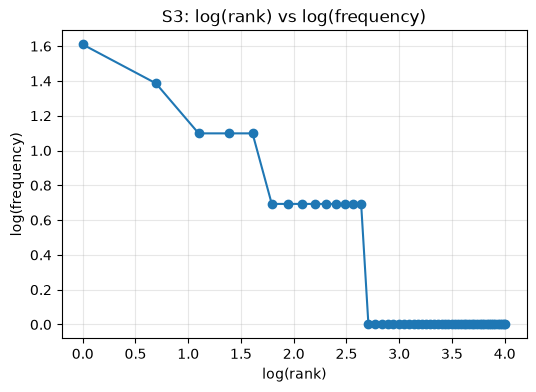

Top 5 bigrams in S1: [(('.', 'i'), 4), (('restarting', 'the'), 3), (('i', 'have'), 3), (('have', 'tried'), 3), (('tried', 'several'), 3)]
Top 5 bigrams in S3: [(('tried', 'several'), 3), (('several', 'times'), 3), (('ca', "n't"), 2), (('tried', 'restarting'), 2), (('use', 'mobile'), 2)]

Words merged by Porter: {'chang': ['change', 'changed'], 'open': ['open', 'opening']}


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from nltk import bigrams

S1 = [t for r in results.values() for t in r["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for r in results.values() for t in r["final"]]
S4 = [porter.stem(t) for t in S3]

stats = []
for name, s in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    stats.append({"Set": name, "Tokens": len(s), "Unique": len(set(s)), "TTR": round(len(set(s)) / len(s), 4)})
print(pd.DataFrame(stats).to_string(index=False))

print("\nTop 10 in S1:", Counter(S1).most_common(10))
print("Top 10 in S3:", Counter(S3).most_common(10))

freq = sorted(Counter(S3).values(), reverse=True)
rank = np.arange(1, len(freq) + 1)
plt.figure(figsize=(6, 4))
plt.plot(np.log(rank), np.log(freq), "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: log(rank) vs log(frequency)")
plt.grid(alpha=0.3)
plt.show()

bi1 = Counter(b for r in results.values() for b in bigrams(r["tokens"]))
bi3 = Counter(b for r in results.values() for b in bigrams(r["final"]))
print("Top 5 bigrams in S1:", bi1.most_common(5))
print("Top 5 bigrams in S3:", bi3.most_common(5))

groups = {}
for w in set(S3):
    groups.setdefault(porter.stem(w), set()).add(w)
print("\nWords merged by Porter:", {k: sorted(v) for k, v in groups.items() if len(v) > 1})

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR goes 0.545 → 0.606 → 0.714 → 0.688.

- S1 to S2: removing punctuation drops 24 tokens but only 5 types. The `.` alone appears 15 times, so the ratio goes up.
- S2 to S3: removing stopwords drops 55 more tokens but only 25 types. Words like *i* (12 times) and *the* (9 times) repeat a lot, so the ratio goes up again.
- S3 to S4: Porter merges *open/opening* into `open` and *change/changed* into `chang`. That takes the unique count from 55 to 53 while the total stays at 77, so TTR drops slightly.

The Zipf plot is roughly a falling line, but with only 77 tokens most words occur once, so the right side is a long flat stretch at frequency 1.

---
## Q6. Interpretation

**(a) Why does TTR change from S1 to S4 in your dataset?**
Punctuation and stopwords are a small number of types that repeat in almost every ticket (`.` 15 times, *i* 12 times, *the* 9 times). Removing them takes away far more tokens than types, so TTR rises from 0.545 (S1) to 0.606 (S2) to 0.714 (S3). Stemming then merges a few words (*open/opening*, *change/changed*), so S4 has fewer types for the same 77 tokens and TTR falls to 0.688.

**(b) Give one example where word_tokenize() and your tokenizer differ.**
In T01, "I can't login": word_tokenize gives `I, ca, n't, login` and mine gives `I, can't, login`. word_tokenize follows Treebank rules and splits the "n't" off as a separate token meaning "not", which leaves the strange `ca`. My regex allows an apostrophe inside a word, so "can't" stays as one token.

**(c) Give one example where stemming produces an undesirable result.**
Porter turns *several* (from "I have tried several times!") into *sever*. That's a real word with a different meaning, so after stemming the ticket looks like it's about cutting something. Other bad ones in my data: *please → pleas*, *deadline → deadlin*, *anything → anyth*.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**
*tried* is tagged VBD. Porter gives *tri*, which isn't a word, while the lemmatizer with pos='v' gives *try*, the correct base verb. Similarly, *changed* (VBD) becomes *change* with the lemmatizer but *chang* with Porter. Because the lemmatizer knows the word is a verb, it can return the real dictionary form instead of just cutting letters off.